In [2]:
import os
os.chdir(r'C:\Users\Javad')
os.getcwd()

'C:\\Users\\Javad'

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df=pd.read_csv('weatherAUS.csv')

In [5]:
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [6]:
df.isna().sum()

Date                 0
Location             0
MinTemp           1485
MaxTemp           1261
Rainfall          3261
Evaporation      62790
Sunshine         69835
WindGustDir      10326
WindGustSpeed    10263
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am      1767
WindSpeed3pm      3062
Humidity9am       2654
Humidity3pm       4507
Pressure9am      15065
Pressure3pm      15028
Cloud9am         55888
Cloud3pm         59358
Temp9am           1767
Temp3pm           3609
RainToday         3261
RainTomorrow      3267
dtype: int64

In [7]:
print(df.shape)

(145460, 23)


### 2 — drop the rows where the TARGET is missing (mandatory, see our plan)

In [8]:
df = df.dropna(subset=['RainTomorrow']).reset_index(drop=True)
print('Rows kept: ', len(df))
print(df['RainTomorrow'].value_counts(normalize=True).round(3))

Rows kept:  142193
RainTomorrow
No     0.776
Yes    0.224
Name: proportion, dtype: float64


### 3 — missingness map: how much is missing, and is it by station?


In [9]:
miss = (df.isna().mean()*100).sort_values(ascending=False)

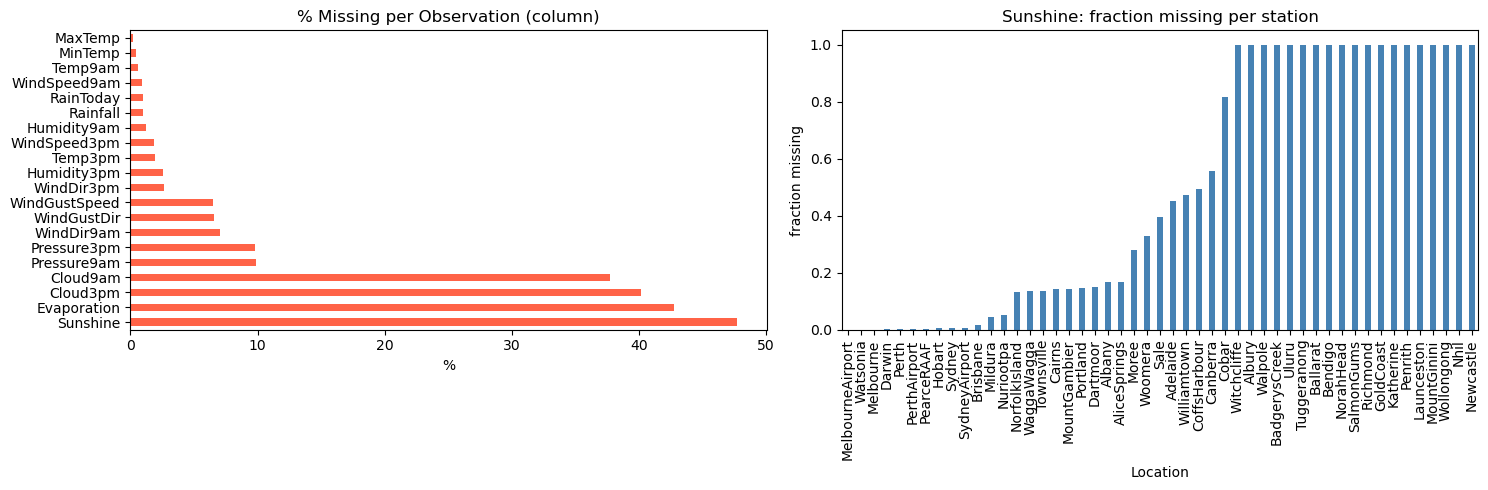

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
miss[miss>0].plot.barh(ax = ax[0], color='tomato')
ax[0].set(title= "% Missing per Observation (column)", xlabel = '%')

# fraction of Sunshine missing per station, to show missingness is structural
by_loc = df.groupby('Location')['Sunshine'].apply(lambda s: s.isna().mean()).sort_values()
by_loc.plot.bar(ax=ax[1], color='steelblue')
ax[1].set(title='Sunshine: fraction missing per station', ylabel = 'fraction missing')
#ax[1].set.xticks([])
plt.tight_layout()
plt.show()


#### 4 — the strongest single predictor you already know: did it rain today?


In [11]:
print(df.groupby('RainToday')['RainTomorrow'].apply(lambda s: (s=='Yes').mean()).round(2))

RainToday
No     0.15
Yes    0.46
Name: RainTomorrow, dtype: float64


#### 5 — which numeric features separate rain from no-rain?


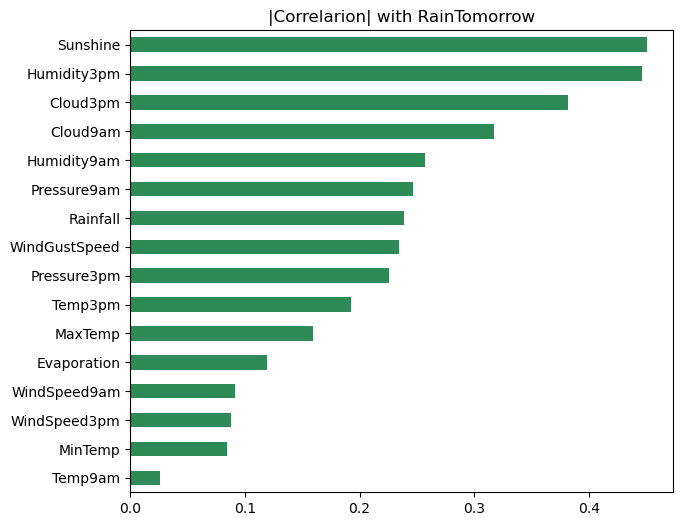

Sunshine         0.45
Humidity3pm      0.45
Cloud3pm         0.38
Cloud9am         0.32
Humidity9am      0.26
Pressure9am      0.25
Rainfall         0.24
WindGustSpeed    0.23
Pressure3pm      0.23
Temp3pm          0.19
MaxTemp          0.16
Evaporation      0.12
WindSpeed9am     0.09
WindSpeed3pm     0.09
MinTemp          0.08
Temp9am          0.03
Name: target, dtype: float64


In [12]:
y=(df['RainTomorrow']=='Yes')
num = df.select_dtypes('number')
corr=num.assign(target=y.astype(int)).corr()['target'].drop('target').abs().sort_values(ascending=False)

corr.plot.barh(figsize=(7,6), color='seagreen')
plt.title('|Correlarion| with RainTomorrow')
plt.gca().invert_yaxis()
plt.show()
print(corr.round(2))


### Same code simplified

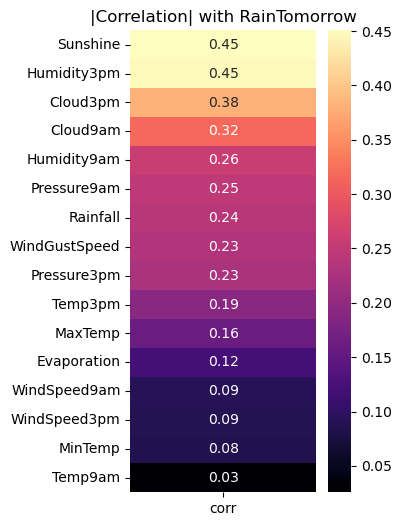

In [13]:
y = (df['RainTomorrow'] == 'Yes')               # 1. boolean: True when it rains tomorrow
num = df.select_dtypes('number').copy()         # 2. keep only the numeric columns
num['target'] = y.astype(int)                   # 3. add the target as 0/1 so it's in the matrix

corr = num.corr()['target']                     # 4a. full correlation matrix, take the 'target' column
corr = corr.drop('target')                      # 4b. remove target's correlation with itself (=1)
corr = corr.abs().sort_values(ascending=False)   # 4c. absolute value, strongest first


plt.figure(figsize=(3, 6))
sns.heatmap(corr.to_frame('corr'),      # one-column frame → vertical strip
            annot=True, fmt='.2f',       # write the number in each cell
            cmap='magma')
plt.title('|Correlation| with RainTomorrow')
plt.show()

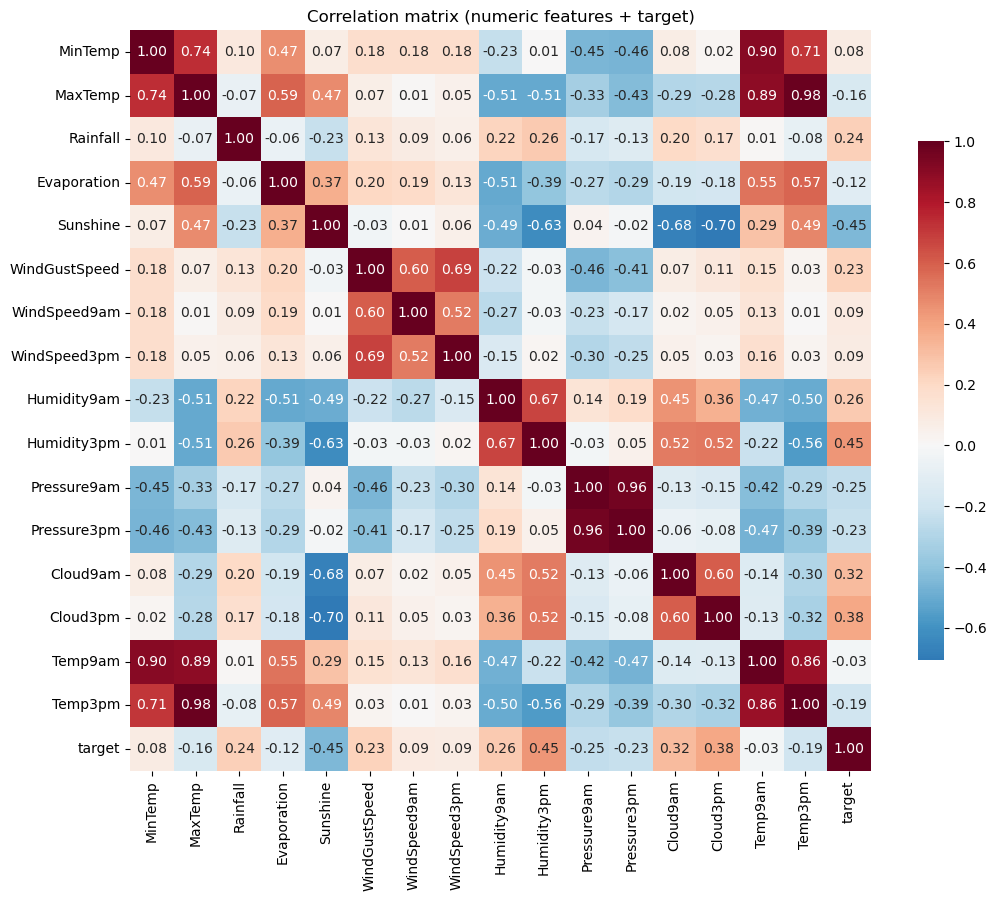

In [14]:
## The whole correlation matrix and heatmap:
plt.figure(figsize=(11, 9))
sns.heatmap(num.corr(),                  # full square matrix
            annot=True, fmt='.2f',
            cmap='RdBu_r', center=0,      # red = positive, blue = negative, white = 0
            square=True, cbar_kws={'shrink': 0.7})
plt.title('Correlation matrix (numeric features + target)')
plt.tight_layout()
plt.show()

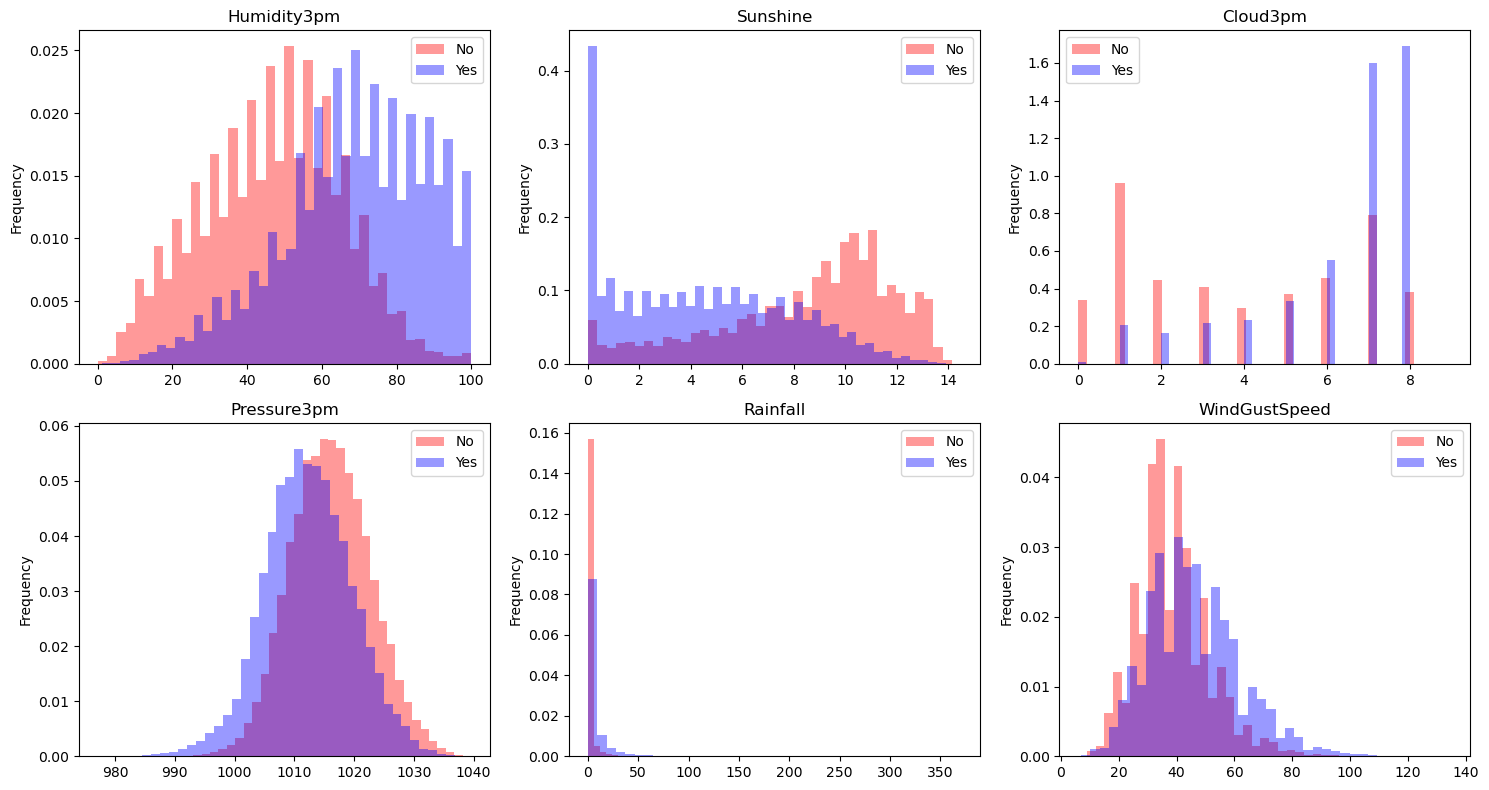

In [15]:
# Select top 6 to plot:
feats = ['Humidity3pm','Sunshine','Cloud3pm','Pressure3pm','Rainfall','WindGustSpeed']

# a grid of 2 rows x 3 columns = 6  plots. 'axes' is a 2x3 array of them.
fig, axes = plt.subplots(2,3, figsize=(15,8))

#   zip pairs each feature with one subplot:
#   axes.ravel() flattens the 2x3 grid into a list of 6, so feature 1 -> plot 1, etc
for f, a in zip (feats, axes.ravel()):
    
    for lab, c in [('No','red'), ('Yes','blue')]: #inner loop runs twice: once for 'No' (blue), once for 'Yes' (red)
        df.loc[df.RainTomorrow==lab, f].plot.hist(
        ax=a, bins=40, alpha=0.4, density=True, label=lab, color=c)
#       df.loc[df.RainTomorrow==lab, f]  = the values of feature f, only for rows of this class
#       .plot.hist(...)                  = draw them as a histogram on subplot 'a'
#         ax=a        -> draw on this specific subplot
#         bins=40     -> 40 bars
#         alpha=0.3   -> 70%-transparent, so the two colours show through each other to see the overlapping areas
#         density=True-> normalise to area 1 (fair when the two classes have different counts)
#         label, color-> for the legend and the colour
    
    
    a.set_title(f)  # title each subplot with the feature name
    a.legend()      # show the No/Yes legend
plt.tight_layout()  # tidy spacing
plt.show()

### Simpler version using seaborn:

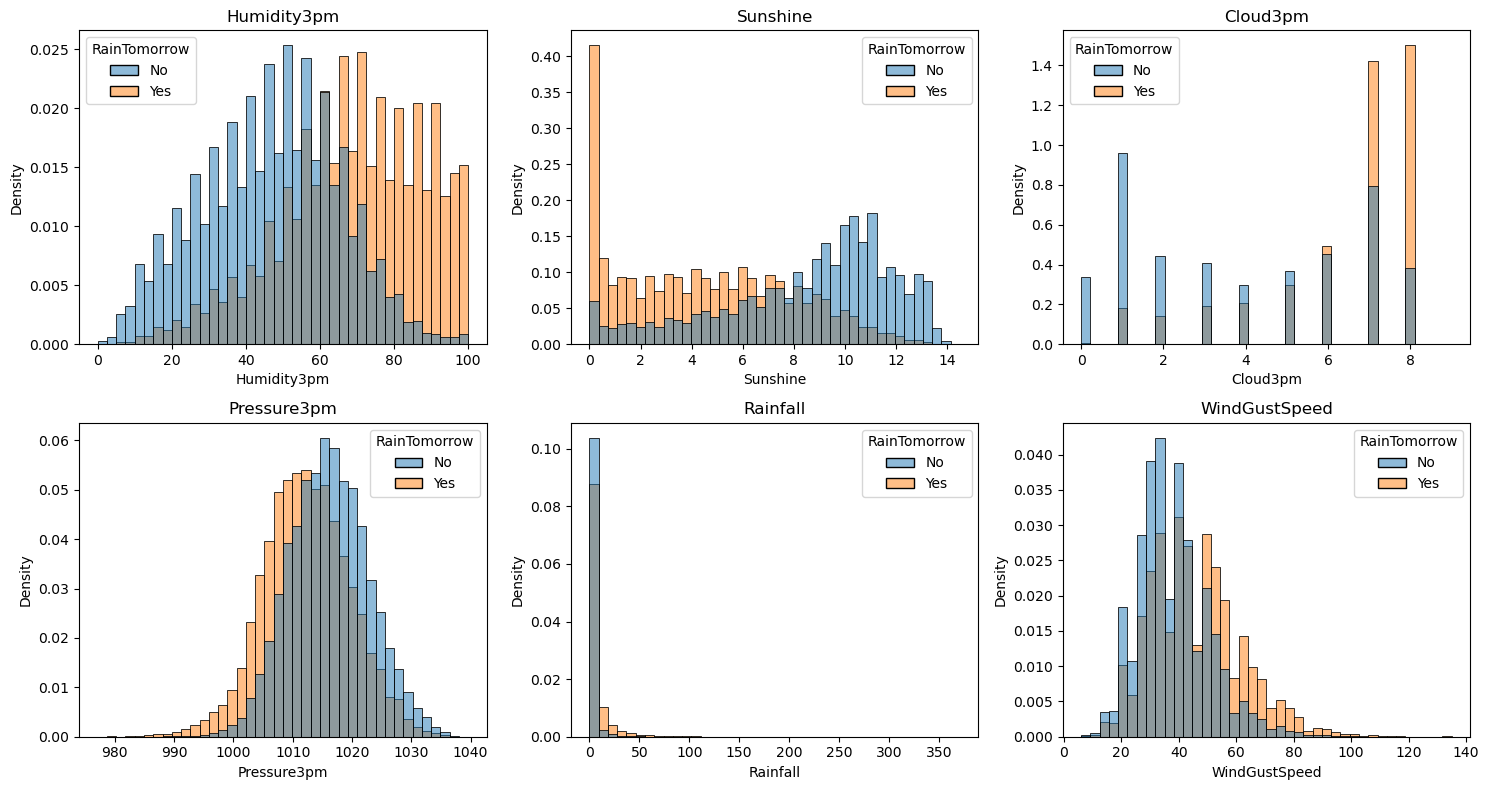

In [16]:
import seaborn as sns
feats = ['Humidity3pm','Sunshine','Cloud3pm','Pressure3pm','Rainfall','WindGustSpeed']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for f, a in zip(feats, axes.ravel()):
    sns.histplot(data=df, x=f, hue='RainTomorrow',   # hue = colour by this column
                 bins=40, stat='density',            # same as density=True
                 common_norm=False,                  # normalise each class separately
                 alpha=0.5, ax=a)
    a.set_title(f)
plt.tight_layout()
plt.show()

### 7 — Mapping seasonality and geography distribution

In [17]:
df['is_rain'] = (df['RainTomorrow'] == 'Yes').astype(int)   # Yes→1, No→0

In [18]:
df['Date'] = pd.to_datetime(df['Date'])          # Convert Date-time which is text to real date time format
df['Month'] = df['Date'].dt.month                # pull the month number (1–12) out of the date

by_month = df.groupby('Month')['is_rain'].mean()  # average is_rain within each month
print(by_month.round(3))

Month
1     0.193
2     0.210
3     0.213
4     0.218
5     0.225
6     0.262
7     0.269
8     0.253
9     0.230
10    0.196
11    0.213
12    0.208
Name: is_rain, dtype: float64


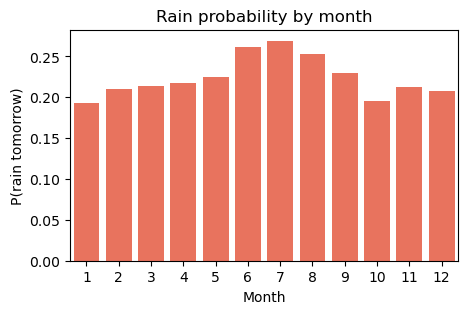

In [19]:

plt.figure(figsize=(5, 3))
sns.barplot(x=by_month.index, y=by_month.values, color='tomato')
plt.title('Rain probability by month')
plt.xlabel('Month')
plt.ylabel('P(rain tomorrow)')
plt.show()

In [20]:
by_loc = df.groupby('Location')['is_rain'].mean().sort_values()   # P(rain) per station, low→high
# print(by_loc)

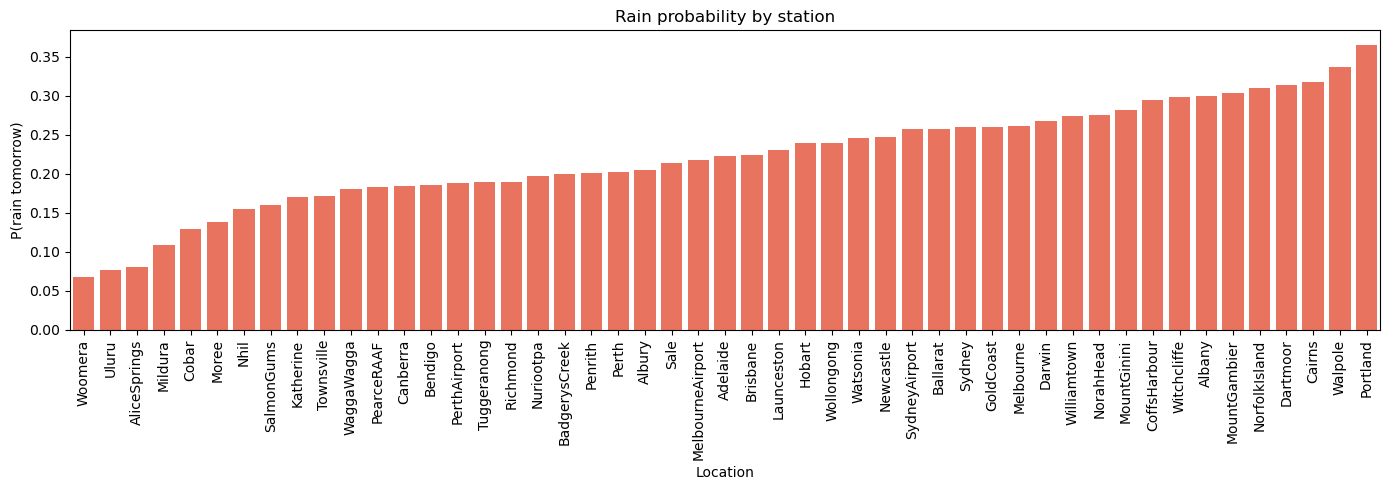

In [21]:
plt.figure(figsize=(14, 5))
sns.barplot(x=by_loc.index, y=by_loc.values, color='tomato')
plt.title('Rain probability by station')
plt.ylabel('P(rain tomorrow)')
plt.xticks(rotation=90)        # 49 station names → rotate so they're readable
plt.tight_layout()
plt.show()

# Step II: prepration of data for modeling


In [22]:
# Convert date col from text to real Date-time format.
df['Date'] = pd.to_datetime(df['Date'])

In [23]:
df.dropna(subset=['RainTomorrow']).reset_index(drop=True)
print('Rows: ', len(df))

Rows:  142193


#### Feature engineering

In [24]:
y = (df['RainTomorrow']=='Yes').astype(int)    # 1 = rain tomorrow, 0 = no

df['Month'] = df['Date'].dt.month              # season signal
df['Year'] = df['Date'].dt.year                # needed for the time split

df['RainToday'] = df['RainToday'].map({'Yes': 1, 'No': 0})   # text → number (NaN kept for imputer)

In [25]:
# Cell 3 — "was it missing?" flags for the heavy columns
heavy = ['Sunshine', 'Evaporation', 'Cloud9am', 'Cloud3pm']
for c in heavy:
    df[c + '_missing'] = df[c].isna().astype(int)           # 1 if this value was missing
flags = [c + '_missing' for c in heavy]

In [26]:
heavy = ['Sunshine', 'Evaporation', 'Cloud9am', 'Cloud3pm'] #The most influential data with highest rate of NA.
for c in heavy:
    df[c + '_missing'] = df[c].isna().astype(int)
    
     # A loop that repeats once per column. Take it apart for one column, say c = 'Sunshine':

    # df['Sunshine'].isna() → a True/False column: True where Sunshine is missing.
    # .astype(int) → turns True/False into 1/0 (models need numbers, not True/False).
    # df['Sunshine' + '_missing'] = ... → saves it as a new column named Sunshine_missing.
    
flag = [c + '_missing' for c in heavy]

 # Just builds the list of the four new names: ['Sunshine_missing', 'Evaporation_missing', 'Cloud9am_missing', 'Cloud3pm_missing']. 
 # We keep this list so we can refer to all four flags later as a group.

In [27]:
# Same code without using loop function:

df['Sunshine_missing']    = df['Sunshine'].isna().astype(int)
df['Evaporation_missing'] = df['Evaporation'].isna().astype(int)
df['Cloud9am_missing']    = df['Cloud9am'].isna().astype(int)
df['Cloud3pm_missing']    = df['Cloud3pm'].isna().astype(int)

flags = ['Sunshine_missing','Evaporation_missing','Cloud9am_missing','Cloud3pm_missing']

In [28]:
df[['Sunshine', 'Sunshine_missing']].head(10)

,Sunshine,Sunshine_missing
0,NaN,1
1,NaN,1
2,NaN,1
3,NaN,1
4,NaN,1
5,NaN,1
6,NaN,1
7,NaN,1
8,NaN,1
9,NaN,1


#### 4 — declare which columns are numeric and which are categorical

In [29]:

heavy_nums = heavy
base_num =['MinTemp','MaxTemp','Rainfall','WindGustSpeed','WindSpeed9am','WindSpeed3pm',
            'Humidity9am','Humidity3pm','Pressure9am','Pressure3pm','Temp9am','Temp3pm',
            'RainToday','Month','Year']

num_cols = base_num + heavy_nums + flag  # This ensures all numerical columns are considered as input
cat_cols = ['Location','WindGustDir','WindDir9am','WindDir3pm'] # Categorical (text) inputs

X = df[num_cols + cat_cols] #Total features table

In [30]:
X.head()

,MinTemp,MaxTemp,Rainfall,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,...,Cloud9am,Cloud3pm,Sunshine_missing,Evaporation_missing,Cloud9am_missing,Cloud3pm_missing,Location,WindGustDir,WindDir9am,WindDir3pm
0,13.4,22.9,0.6,44.0,20.0,24.0,71.0,22.0,1007.7,1007.1,...,8.0,NaN,1,1,0,1,Albury,W,W,WNW
1,7.4,25.1,0.0,44.0,4.0,22.0,44.0,25.0,1010.6,1007.8,...,NaN,NaN,1,1,1,1,Albury,WNW,NNW,WSW
2,12.9,25.7,0.0,46.0,19.0,26.0,38.0,30.0,1007.6,1008.7,...,NaN,2.0,1,1,1,0,Albury,WSW,W,WSW
3,9.2,28.0,0.0,24.0,11.0,9.0,45.0,16.0,1017.6,1012.8,...,NaN,NaN,1,1,1,1,Albury,NE,SE,E
4,17.5,32.3,1.0,41.0,7.0,20.0,82.0,33.0,1010.8,1006.0,...,7.0,8.0,1,1,0,0,Albury,W,ENE,NW


##### 5 — THE TIME-BASED SPLIT (train on the past, test on the future)

In [31]:
cutoff = '2016-01-01'
train_mask = df['Date'] < cutoff   # Before 2016 = train set
test_mask = ~train_mask            # 2016 and onwrad = tets set

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print('train:', X_train.shape, '| test:', X_test.shape)
print('train rain rate:', y_train.mean().round(2), '| test rain rate:', y_test.mean().round(2))

train: (116219, 27) | test: (25974, 27)
train rain rate: 0.22 | test rain rate: 0.23


 #### 6. Defifing a pipeline for data transformation, Onehotencoding and fitting 

In [32]:
from sklearn.compose import ColumnTransformer   # This modules treats different columns in different ways. Scaling of numberic and Onehot encoding for categorical
from sklearn.pipeline import Pipeline           # chain preprocessing + model into one object
from sklearn.impute import SimpleImputer        # For treting of missing values
from sklearn.preprocessing import StandardScaler, OneHotEncoder
 
# ColumnTransformer applies the right recipe to each column group in one object. 
    
num_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),   # this code fills numeric gaps with the median
    ('scale', StandardScaler())                     # mean 0, SD 1 (helps linear models / NN)
])

cat_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),  # fill text gaps with the commonest value
    ('onehot', OneHotEncoder(handle_unknown='ignore'))    # # categories → 0/1 columns; ignore unseen ones
# handle_unknown='ignore' protects you if a category appears only in the test years.
])

preprocess = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

##### 7 — fit on TRAIN only, then apply to both (this is what prevents leakage)


In [39]:
X_train_t = preprocess.fit_transform(X_train)        # learns medians, means, categories from TRAIN
X_test_t = preprocess.transform(X_test)          # applies those SAME numbers to TEST

print('Transfromed: ', X_train_t.shape, X_test_t.shape)

Transfromed:  (116219, 120) (25974, 120)


# Step III: Running of Basic Models:

#### 1 — the "do nothing" baseline


In [40]:
print("Always predict 'No rain': ", round((y_test == 0).mean(), 3))

# Always guessing “No” scores 0.77. Any model must beat this to be worth anything. 
# This is why accuracy alone is a trap on imbalanced data.

Always predict 'No rain':  0.771


#### 2 — import the metrics


In [41]:
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score, classification_report

#### 3 — logistic regression on top of your preprocessing

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

LogReg = Pipeline([
    ('pre', preprocess),                        # This is the column transformer from step 3
    ('clf', LogisticRegression(max_iter=1000))  # 
])
LogReg.fit(X_train, y_train)

,steps,"[('pre', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


#####  4 — score it


In [43]:
pred = LogReg.predict(X_test)
proba = LogReg.predict_proba(X_test)[:, 1]   # Prediction for raining

print('Accuracy: ', round(accuracy_score(y_test, pred), 3))
print('ROC-AUC:  ', round(roc_auc_score(y_test, proba), 3))
print('PR-AUC:   ', round(average_precision_score(y_test, proba), 3))
print(classification_report(y_test, pred))

Accuracy:  0.841
ROC-AUC:   0.856
PR-AUC:    0.686
              precision    recall  f1-score   support

           0       0.86      0.94      0.90     20028
           1       0.72      0.50      0.59      5946

    accuracy                           0.84     25974
   macro avg       0.79      0.72      0.75     25974
weighted avg       0.83      0.84      0.83     25974



# Trying different MODELS on dataset

In [44]:
# IMPORTANT: HistGradientBoosting needs DENSE input, so make the one-hot dense.
# In your Step-3 ColumnTransformer, change the encoder to:
OneHotEncoder(handle_unknown='ignore', sparse_output=False)

,categories,'auto'
,drop,None
,sparse_output,False
,dtype,<class 'numpy.float64'>
,handle_unknown,'ignore'
,min_frequency,None
,max_categories,None
,feature_name_combiner,'concat'


## Model 1: Random forest

In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

rf = Pipeline([
    ('pre', preprocess),
    ('clf', RandomForestClassifier(n_estimators=200, max_depth=20,
                                  class_weight='balanced', n_jobs=-1, random_state=42))
])

rf.fit(X_train, y_train)

proba_rf = rf.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, proba_rf), 3),
"| PR-AUC:", round(average_precision_score(y_test, proba_rf), 3))

ROC-AUC: 0.867 | PR-AUC: 0.699


In [48]:
pred_rf = rf.predict(X_test)
proba_rf = rf.predict_proba(X_test)[:, 1]  

print('Accuracy: ', round(accuracy_score(y_test, pred_rf), 3))
print('ROC-AUC:  ', round(roc_auc_score(y_test, proba_rf), 3))
print('PR-AUC:   ', round(average_precision_score(y_test, proba_rf), 3))
print(classification_report(y_test, pred_rf))

Accuracy:  0.838
ROC-AUC:   0.867
PR-AUC:    0.699
              precision    recall  f1-score   support

           0       0.89      0.91      0.90     20028
           1       0.66      0.61      0.63      5946

    accuracy                           0.84     25974
   macro avg       0.77      0.76      0.76     25974
weighted avg       0.83      0.84      0.84     25974



## Model 2: HistGradientBoosting

In [54]:
# HistGradientBoosting needs dense input. In Step-3 preprocess, change the one-hot encoder: and add: sparse_output= False

from sklearn.compose import ColumnTransformer   # This modules treats different columns in different ways. Scaling of numberic and Onehot encoding for categorical
from sklearn.pipeline import Pipeline           # chain preprocessing + model into one object
from sklearn.impute import SimpleImputer        # For treting of missing values
from sklearn.preprocessing import StandardScaler, OneHotEncoder
 
# ColumnTransformer applies the right recipe to each column group in one object. 
    
num_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),   # this code fills numeric gaps with the median
    ('scale', StandardScaler())                     # mean 0, SD 1 (helps linear models / NN)
])

cat_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),  # fill text gaps with the commonest value
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output= False))    # # categories → 0/1 columns; ignore unseen ones
# handle_unknown='ignore' protects you if a category appears only in the test years.
])

preprocess = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])


In [55]:
# Cell 2 — boosting: each tree fixes the previous trees' mistakes
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = Pipeline([
    ('pre', preprocess),
    ('clf', HistGradientBoostingClassifier(max_iter=300, learning_rate=0.07, random_state=42))
]).fit(X_train, y_train)

proba_hgb = hgb.predict_proba(X_test)[:, 1]   # ✓ probability of rain (column 1)
print("ROC-AUC:", round(roc_auc_score(y_test, proba_hgb), 3),
      "| PR-AUC:", round(average_precision_score(y_test, proba_hgb), 3))

ROC-AUC: 0.879 | PR-AUC: 0.728


In [57]:
from sklearn.ensemble import HistGradientBoostingClassifier   # ✓ Classifier

hgb = Pipeline([
    ('pre', preprocess),
    ('clf', HistGradientBoostingClassifier(max_iter=300, learning_rate=0.07, random_state=42))
])
hgb.fit(X_train, y_train)

proba_hgb = hgb.predict_proba(X_test)[:, 1]    # ✓ probability of rain (column 1)
pred_hgb  = hgb.predict(X_test)                # ✓ 0/1 labels

from sklearn.metrics import roc_auc_score, average_precision_score
print("ROC-AUC:", round(roc_auc_score(y_test, proba_hgb), 3),
      "| PR-AUC:", round(average_precision_score(y_test, proba_hgb), 3))


ROC-AUC: 0.879 | PR-AUC: 0.728


In [58]:
pred_hgb = hgb.predict(X_test)
proba_hgb = hgb.predict_proba(X_test)[:, 1]  

print('Accuracy: ', round(accuracy_score(y_test, pred_hgb), 3))
print('ROC-AUC:  ', round(roc_auc_score(y_test, proba_hgb), 3))
print('PR-AUC:   ', round(average_precision_score(y_test, proba_hgb), 3))
print(classification_report(y_test, pred_hgb))

Accuracy:  0.851
ROC-AUC:   0.879
PR-AUC:    0.728
              precision    recall  f1-score   support

           0       0.88      0.94      0.91     20028
           1       0.73      0.55      0.63      5946

    accuracy                           0.85     25974
   macro avg       0.80      0.75      0.77     25974
weighted avg       0.84      0.85      0.84     25974



## Model 3: LightGBM (the winner)

In [59]:
import sys
!"{sys.executable}" -m pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ----------------------- ---------------- 0.8/1.4 MB 4.8 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 5.4 MB/s  0:00:00

   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   -------------------- ------------------- 1/2 [lightgbm]
   -------------------- ------------------- 1/2 [lightgbm]
   ---------------------------------------- 2/2 [lightgbm]



In [ ]:
# Cell 4 — the strongest model
from lightgbm import LGBMClassifier

lgbm = Pipeline([
    ('pre', preprocess),
    ('clf', LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=48,
                           class_weight='balanced', n_jobs=-1, random_state=42))
]).fit(X_train, y_train)

proba_lgbm = lgbm.predict_proba(X_test)[:, 1]  # ✓ probability of rain (column 1)
pred_lgbm  = lgbm.predict(X_test)
print("ROC-AUC:", round(roc_auc_score(y_test, proba_lgbm), 3),
      "| PR-AUC:", round(average_precision_score(y_test, proba_lgbm), 3))
print(classification_report(y_test, pred_lgbm))

In [62]:
from lightgbm import LGBMClassifier

lgbm = Pipeline([
    ('pre', preprocess),
    ('clf', LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=48,
                          class_weight='balanced', n_jobs=-1, random_state=42))
])
lgbm.fit(X_train, y_train)

proba_lgbm = lgbm.predict_proba(X_test)[:, 1]   # ✓ probability of rain (column 1)

pred_lgbm = lgbm.predict(X_test)

print("ROC-AUC:", round(roc_auc_score(y_test, proba_lgbm), 3),
      "| PR-AUC:", round(average_precision_score(y_test, proba_lgbm), 3))
print(classification_report(y_test, pred_lgbm))

[LightGBM] [Info] Number of positive: 25931, number of negative: 90288
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004094 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2762
[LightGBM] [Info] Number of data points in the train set: 116219, number of used features: 120
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
ROC-AUC: 0.882 | PR-AUC: 0.732
              precision    recall  f1-score   support

           0       0.93      0.81      0.86     20028
           1       0.55      0.80      0.65      5946

    accuracy                           0.80     25974
   macro avg       0.74      0.80      0.76     25974
weighted avg       0.84      0.80      0.81     25974



In [63]:
pred_lgbm = lgbm.predict(X_test)
proba_hgb = lgbm.predict_proba(X_test)[:, 1]  

print('Accuracy: ', round(accuracy_score(y_test, pred_lgbm), 3))
print('ROC-AUC:  ', round(roc_auc_score(y_test, proba_lgbm), 3))
print('PR-AUC:   ', round(average_precision_score(y_test, proba_lgbm), 3))
print(classification_report(y_test, pred_lgbm))

Accuracy:  0.803
ROC-AUC:   0.882
PR-AUC:    0.732
              precision    recall  f1-score   support

           0       0.93      0.81      0.86     20028
           1       0.55      0.80      0.65      5946

    accuracy                           0.80     25974
   macro avg       0.74      0.80      0.76     25974
weighted avg       0.84      0.80      0.81     25974



##### Compare tdifferent models on one plot

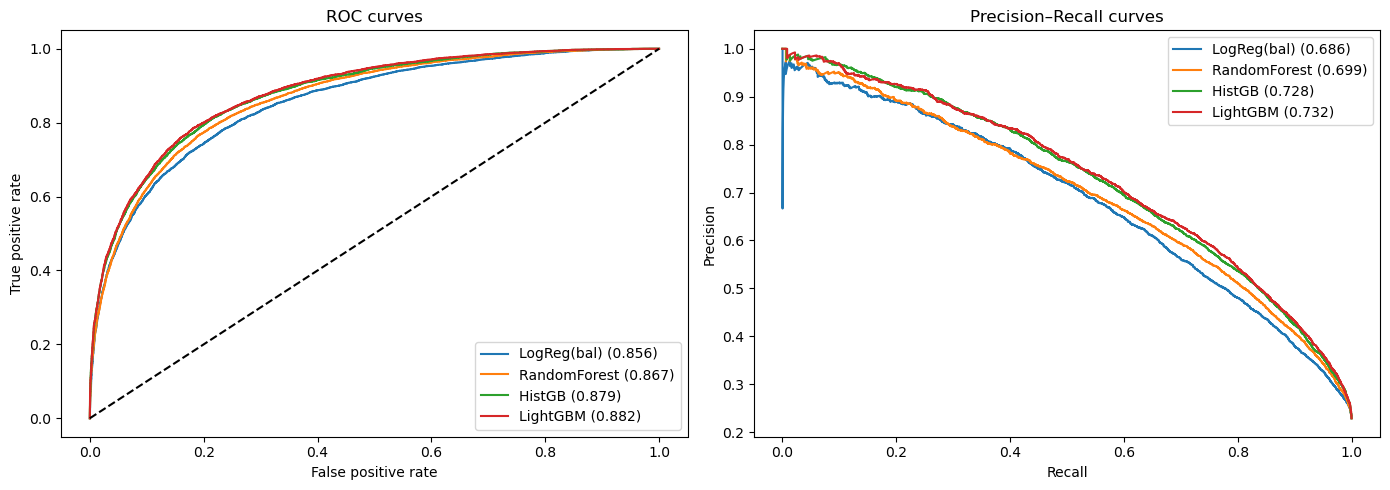

In [67]:
#5 — ROC and PR curves, all models together

from sklearn.metrics import roc_curve, precision_recall_curve

models = {'LogReg(bal)': proba, 'RandomForest': proba_rf,
          'HistGB': proba_hgb, 'LightGBM': proba_lgbm}      # proba_b from Step 4

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, pr in models.items():
    fpr, tpr, _ = roc_curve(y_test, pr)
    ax[0].plot(fpr, tpr, label=f'{name} ({roc_auc_score(y_test, pr):.3f})')
    prec, rec, _ = precision_recall_curve(y_test, pr)
    ax[1].plot(rec, prec, label=f'{name} ({average_precision_score(y_test, pr):.3f})')
ax[0].plot([0,1],[0,1],'k--'); ax[0].set(title='ROC curves', xlabel='False positive rate', ylabel='True positive rate')
ax[1].set(title='Precision–Recall curves', xlabel='Recall', ylabel='Precision')
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()

##### Do we Need all Features to be incorpporated in to the model?

Many features are redundant (Temp9am, Temp3pm, MinTemp, MaxTemp all say similar things) or weak, so removing them doesn’t hurt.

The three families of feature selection

1. Filter methods (fast, model-free): rank features by a simple statistic, correlation with the target, or $SelectKBest$ with mutual information. Cheap, but ignores how features interact.

2. Embedded methods (the model selects): the model gives importances for free.

Trees: model.feature_importances_
Linear with L1 penalty (LogisticRegression(penalty='l1')): shrinks useless coefficients to exactly 0.
Permutation importance (what I used above): the most honest, measures real effect on the score.

3. Wrapper methods ($“forward -and  -backward”$): repeatedly train the model with different feature subsets and keep the best. Most accurate, most expensive.

##### 1.Forward selection (start empty, add the best one at a time):

In [70]:
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression

# forward selection: start with NO features, add the one that helps most, repeat.
sfs = SequentialFeatureSelector(LogisticRegression(max_iter=1000),
                               n_features_to_select=10,
                               direction='forward',  
                                scoring='roc_auc', cv=3, n_jobs=-1)  # judge each addition by 3-fold CV AUC

X_train_t = preprocess.fit_transform(X_train)        # text → numeric first (fit on train only)

sfs.fit(X_train_t, y_train)

print("features selected:", sfs.get_support().sum())

features selected: 10


In [72]:
print(sfs)

SequentialFeatureSelector(cv=3, estimator=LogisticRegression(max_iter=1000),
                          n_features_to_select=10, n_jobs=-1,
                          scoring='roc_auc')


#### Backward elimination:
Backward elimination (start full, remove the weakest one at a time). scikit-learn’s $RFE$ (RFE = Recursive Feature Elimination) does exactly this:

In [75]:
from sklearn.feature_selection import RFE             #(Recrusive Feature Elimination)
from sklearn.ensemble import RandomForestClassifier

# NOTE: run RFE on already-preprocessed (numeric) data, X_train_t
selector = RFE(estimator=RandomForestClassifier(n_estimators=100, random_state=42),
               n_features_to_select = 12,      # target size
               step =2)                        # remove 2 at each round

selector.fit(X_train_t, y_train) # selector.support_ is a True/False mask of the kept columns
        

,estimator,RandomForestC...ndom_state=42)
,n_features_to_select,12
,step,2
,verbose,0
,importance_getter,'auto'
,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0


In [76]:
selector.support_

array([ True,  True,  True,  True, False,  True,  True,  True,  True,
        True,  True,  True, False, False, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False])

#### The practical recipe I’d actually use

#### =====================================================================
###### FEATURE-SELECTION METHOD COMPARISON  —  single self-contained cell
###### Needs only: X_train, X_test, y_train, y_test  (from your Step-3 split)
###### ===========================================================================

In [79]:
# =====================================================================
#  FEATURE-SELECTION METHOD COMPARISON  —  single self-contained cell
#  Needs only: X_train, X_test, y_train, y_test  (from your Step-3 split)
# =====================================================================
import numpy as np, pandas as pd, warnings; warnings.filterwarnings('ignore')
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.metrics import roc_auc_score

# ---- 1. column lists (defined HERE so nothing depends on earlier cells) ----
flags    = ['Sunshine_missing','Evaporation_missing','Cloud9am_missing','Cloud3pm_missing']
num_cols = ['MinTemp','MaxTemp','Rainfall','WindGustSpeed','WindSpeed9am','WindSpeed3pm',
            'Humidity9am','Humidity3pm','Pressure9am','Pressure3pm','Temp9am','Temp3pm',
            'RainToday','Month','Year','Sunshine','Evaporation','Cloud9am','Cloud3pm'] + flags
cat_cols = ['Location','WindGustDir','WindDir9am','WindDir3pm']
feature_cols = num_cols + cat_cols

# ---- 2. preprocessor builder (works for any subset of columns) ----
def build_preprocess(cols):
    n = [c for c in cols if c in num_cols]
    c = [c for c in cols if c in cat_cols]
    return ColumnTransformer([
        ('num', Pipeline([('i', SimpleImputer(strategy='median')), ('s', StandardScaler())]), n),
        ('cat', Pipeline([('i', SimpleImputer(strategy='most_frequent')),
                          ('o', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), c)])

# ---- 3. map transformed columns back to original features ----
pre_all = build_preprocess(feature_cols).fit(X_train)
tnames  = pre_all.get_feature_names_out()                # 'num__Humidity3pm', 'cat__Location_Albury', ...
orig    = []
for t in tnames:
    base = t.split('__', 1)[1]
    if t.startswith('num__'):
        orig.append(base)
    else:
        orig.append(next((c for c in cat_cols if base.startswith(c + '_')), base))
orig = np.array(orig)
def to_orig(scores):                                     # sum per-dummy scores up to the original feature
    return pd.Series(scores, index=orig).groupby(level=0).sum()

# ---- 4. run the four selection methods on a 25k subsample (for speed) ----
idx = X_train.sample(25000, random_state=0).index
Xs  = pre_all.transform(X_train.loc[idx])
ys  = y_train.loc[idx]
rank = {}

mi = mutual_info_classif(Xs, ys, random_state=0)                                     # FILTER
rank['MutualInfo']   = to_orig(mi).sort_values(ascending=False)

l1 = LogisticRegression(penalty='l1', solver='liblinear', C=0.1,                     # EMBEDDED (linear)
                        class_weight='balanced', max_iter=500).fit(Xs, ys)
rank['L1-Logistic']  = to_orig(np.abs(l1.coef_[0])).sort_values(ascending=False)

rf = RandomForestClassifier(n_estimators=150, max_depth=18, n_jobs=-1,               # EMBEDDED (tree)
                            random_state=42).fit(Xs, ys)
rank['RF-importance'] = to_orig(rf.feature_importances_).sort_values(ascending=False)

rfe = RFE(RandomForestClassifier(n_estimators=60, max_depth=14, n_jobs=-1,           # WRAPPER (backward)
          random_state=42), n_features_to_select=1, step=3).fit(Xs, ys)
rank['RFE-backward'] = pd.Series(rfe.ranking_, index=orig).groupby(level=0).min().sort_values()

# ---- 5. ONE fixed evaluator, so we compare methods not classifiers ----
def eval_topk(feats):
    m = Pipeline([('pre', build_preprocess(feats)),
                  ('clf', HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=42))
                 ]).fit(X_train[feats], y_train)
    return roc_auc_score(y_test, m.predict_proba(X_test[feats])[:, 1])

# ---- 6. compare, print table, show the agreed-on features ----
K = 12
selections = {}
print(f"Feature-selection comparison (evaluator = HGB, top-{K}):\n")
for name, r in rank.items():
    feats = list(r.head(K).index)
    selections[name] = set(feats)
    print(f"{name:14s} AUC = {eval_topk(feats):.4f}")
print(f"\nAll-{len(feature_cols)} reference AUC = {eval_topk(feature_cols):.4f}")
print(f"\nChosen by ALL methods: {sorted(set.intersection(*selections.values()))}")

# keep the rankings for the next step
feature_rankings = rank

Feature-selection comparison (evaluator = HGB, top-12):

MutualInfo     AUC = 0.8731
L1-Logistic    AUC = 0.8750
RF-importance  AUC = 0.8766
RFE-backward   AUC = 0.8642

All-27 reference AUC = 0.8776

Chosen by ALL methods: ['Cloud3pm', 'Humidity3pm', 'Pressure3pm', 'Pressure9am', 'Sunshine', 'WindGustSpeed']


In [80]:
selected_features = list(feature_rankings['RF-importance'].head(12).index)
print(selected_features)
# now re-run just your chosen classifier on X_train[selected_features]

['Humidity3pm', 'Location', 'Rainfall', 'Sunshine', 'Pressure3pm', 'Humidity9am', 'Pressure9am', 'WindGustSpeed', 'Temp3pm', 'Cloud3pm', 'WindDir3pm', 'WindDir9am']


In [81]:
# ===== FINAL MODEL on the six selected features, choosen by all methods (the 6 all methods agreed on) =====
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, classification_report

# Option B: the consensus features (same objects as the comparison cell)
selected_features = sorted(set.intersection(*selections.values()))
print("Using", len(selected_features), "features:", selected_features)

final_model = Pipeline([
    ('pre', build_preprocess(selected_features)),
    ('clf', LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=48,
                           class_weight='balanced', random_state=42, n_jobs=-1))
]).fit(X_train[selected_features], y_train)

proba = final_model.predict_proba(X_test[selected_features])[:, 1]
pred  = final_model.predict(X_test[selected_features])

print("Test AUC:", round(roc_auc_score(y_test, proba), 4))
print(classification_report(y_test, pred, digits=3))

Using 6 features: ['Cloud3pm', 'Humidity3pm', 'Pressure3pm', 'Pressure9am', 'Sunshine', 'WindGustSpeed']
[LightGBM] [Info] Number of positive: 25931, number of negative: 90288
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002243 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 810
[LightGBM] [Info] Number of data points in the train set: 116219, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Test AUC: 0.8505
              precision    recall  f1-score   support

           0      0.912     0.780     0.841     20028
           1      0.502     0.748     0.601      5946

    accuracy                          0.773     25974
   macro avg      0.707     0.764     0.721     25974
weighted avg      0.819     0.773     0.786     259

In [82]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             precision_recall_fscore_support)
from lightgbm import LGBMClassifier

def run(cols):
    m = Pipeline([('pre', build_preprocess(cols)),
                  ('clf', LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=48,
                                         class_weight='balanced', random_state=42, n_jobs=-1))
                 ]).fit(X_train[cols], y_train)
    proba = m.predict_proba(X_test[cols])[:, 1]
    pred  = m.predict(X_test[cols])
    P, R, F, _ = precision_recall_fscore_support(y_test, pred, labels=[1], average=None)  # rain class
    return {'Features': len(cols), 'Accuracy': accuracy_score(y_test, pred),
            'ROC_AUC': roc_auc_score(y_test, proba), 'PR_AUC': average_precision_score(y_test, proba),
            'Precision_rain': P[0], 'Recall_rain': R[0], 'F1_rain': F[0]}

comparison = pd.DataFrame({
    'Before (all 27)':    run(feature_cols),        # all features
    'After (6 features)': run(selected_features)     # Option-B consensus set
}).T
print(comparison.round(4).to_string())

[LightGBM] [Info] Number of positive: 25931, number of negative: 90288
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002738 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2762
[LightGBM] [Info] Number of data points in the train set: 116219, number of used features: 120
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Info] Number of positive: 25931, number of negative: 90288
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000886 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 810
[LightGBM] [Info] Number of data points in the train set: 116219, number of used features: 6
[LightGBM] [Info] [